In [6]:
pip install engineering-notation

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


819.81f ∠ 123.69°
113.69f ∠ 90°
----------------------------
[['2.61k ∠ 46.63°']
 ['1.58k ∠ -40.90°']
 ['2.42k ∠ 171.80°']]
----------------------------
[['1.45 ∠ 46.63°']
 ['2.37k ∠ -40.90°']
 ['2.42k ∠ 171.80°']]
----------------------------


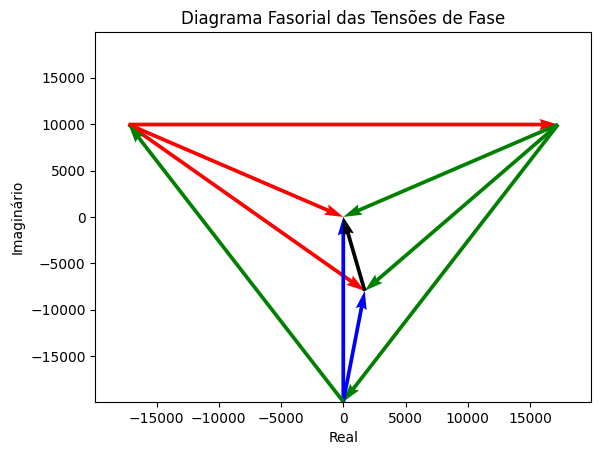

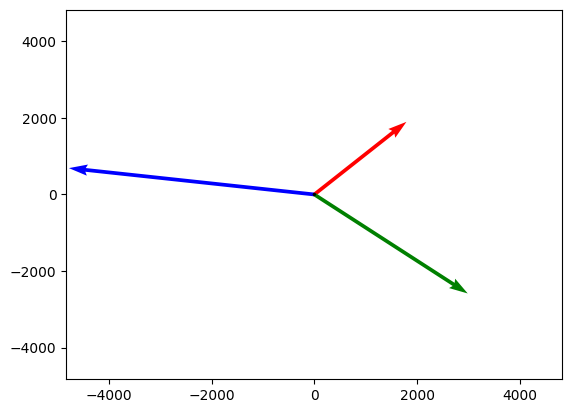

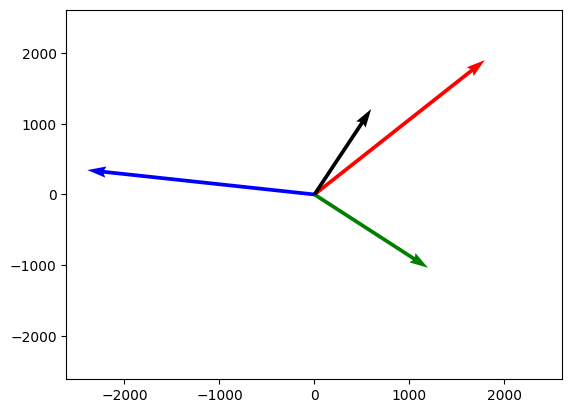

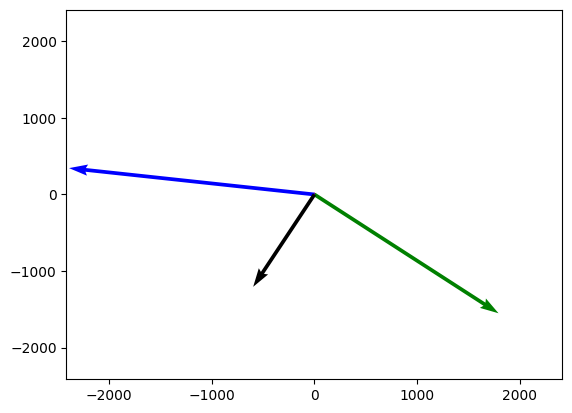

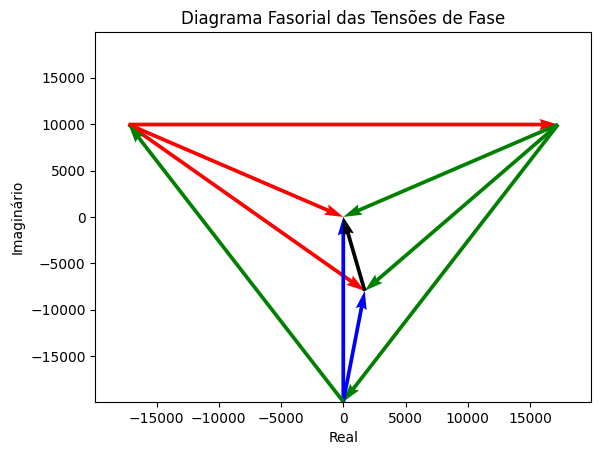

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from engineering_notation import EngNumber


def eng_complex(c):
    real = EngNumber(c.real)
    imag = EngNumber(abs(c.imag))
    sign = '+' if c.imag >= 0 else '-'
    return f"{real} {sign} j{imag}"


def eng_complex_polar(c):
    magnitude = EngNumber(abs(c))
    angle = EngNumber(np.angle(c, deg=True))
    return f"{magnitude} ∠ {angle}°"


def eng_complex_matrix(matrix):
    shape = matrix.shape
    formatted_matrix = np.empty(shape, dtype=object)

    for i in range(shape[0]):
        for j in range(shape[1]):
            formatted_matrix[i, j] = eng_complex(matrix[i, j])

    return formatted_matrix


def eng_complex_polar_matrix(matrix):
    shape = matrix.shape
    formatted_matrix = np.empty(shape, dtype=object)

    for i in range(shape[0]):
        for j in range(shape[1]):
            formatted_matrix[i, j] = eng_complex_polar(matrix[i, j])

    return formatted_matrix



class ComplexoJ(complex):
    def __str__(self):
        if self.imag < 0:
            return f"{self.real}-j{-self.imag}"
        else:
            return f"{self.real}+j{self.imag}"


class Impedancia:
    def __init__(self, resistencia, reatancia):
        self.resistencia = resistencia
        self.reatancia = reatancia

    def as_complex_for_print(self):
        return f"{self.resistencia}+𝒿{self.reatancia}"

    def as_complex(self):
        return complex(self.resistencia, self.reatancia)

    def modulo(self):
        return (self.resistencia ** 2 + self.reatancia ** 2) ** 0.5

    def angulo(self):
        return np.atan2(self.reatancia, self.resistencia) * 180 / np.pi

    def em_paralelo(self, other):
        Y1 = 1 / (self.resistencia + 1j * self.reatancia)
        Y2 = 1 / other
        Yp = Y1 + Y2
        Zp = 1 / Yp
        return Zp


def format_complex_number(number):
    real_part = number.real
    imaginary_part = number.imag
    return f"{real_part} + 𝒿{imaginary_part}"


class MatrizImpedancia:
    def __init__(self, Zabc, configuracao):
        self.configuracao = configuracao
        zaa = Zabc[0, 0]
        zbb = Zabc[1, 1]
        zcc = Zabc[2, 2]
        zab = Zabc[0, 1]
        zac = Zabc[0, 2]
        zbc = Zabc[1, 2]
        if configuracao == 'y_aterrado':
            self.imp_matrix = Zabc
        if configuracao == 'y_isolado':
            self.imp_matrix = np.array(
                [[zaa + zbb, -zbb],
                 [-zbb, zbb + zcc]])

    def matriz(self):
        return self.imp_matrix


class Fonte_trifasica:
    def __init__(self, v_ab, config):
        self.v_ab = v_ab
        self.v_bc = v_ab * np.exp(-1j * 2 * np.pi / 3)
        self.v_ca = v_ab * np.exp(+1j * 2 * np.pi / 3)
        self.config = config

    def vetor_tensoes(self):
        Vabc = [[self.v_ab], [self.v_bc], [self.v_ca]]
        return np.array(Vabc)


def rectangular_para_polar(z):
    magnitude = np.abs(z)
    angulo = np.angle(z, deg=True)  # Use deg=False para obter o ângulo em radianos
    return f"{magnitude}  ∠ {angulo}°"

def plot_diagrama_fasorial(Vabco, v_ab):
    # limite de escala do gráfico
    lim = np.abs(v_ab/np.sqrt(3))

    Vao = Vabco[0]
    Vbo = Vabco[1]
    Vco = Vabco[2]

    a = np.exp(-2j*np.pi/3)
    v_bc = v_ab * a
    v_ca = v_ab * a**2

    b = np.exp(-1j*np.pi/6)
    Van = v_ab * b / np.sqrt(3)
    Vbn = Van * a
    Vcn = Van * a **2

    # Vabco = np.array([[Vao], [Vbo], [Vco]])
    Vabcn = np.array([[Van], [Vbn], [Vcn]])
    Von = Vabcn - Vabco
    Vonx, Vony = np.real(Von[0]), np.imag(Von[0])

    Vanx, Vany = np.real(Van), np.imag(Van)
    Vbnx, Vbny = np.real(Vbn), np.imag(Vbn)
    Vcnx, Vcny = np.real(Vcn), np.imag(Vcn)


    Vabx, Vaby = np.real(v_ab), np.imag(v_ab)
    Vbcx, Vbcy = np.real(v_bc), np.imag(v_bc)
    Vcax, Vcay = np.real(v_ca), np.imag(v_ca)

    Vaox, Vaoy = np.real(Vao), np.imag(Vao)
    Vbox, Vboy = np.real(Vbo), np.imag(Vbo)
    Vcox, Vcoy = np.real(Vco), np.imag(Vco)

    fasorial = plt.figure()
    x0 = -Vanx
    y0 = -Vany
    plt.quiver(x0, y0, Vaox, Vaoy, color='r', angles='xy', scale_units='xy', scale=1,  linewidths=0.5)
    plt.quiver(x0, y0, Vanx, Vany, color='r', angles='xy', scale_units='xy', scale=1, linewidths=0.5)
    plt.quiver(x0, y0, Vabx, Vaby, color='r', angles='xy', scale_units='xy', scale=1,  lw=0.5)
    x0 = -Vbnx
    y0 = -Vbny
    plt.quiver(x0, y0, Vbox, Vboy, color='g', angles='xy', scale_units='xy', scale=1,  lw=0.5)
    plt.quiver(x0, y0, Vbnx, Vbny, color='g', angles='xy', scale_units='xy', scale=1, lw=0.5)
    plt.quiver(x0, y0, Vbcx, Vbcy, color='g', angles='xy', scale_units='xy', scale=1, lw=0.5)
    x0 = -Vcnx
    y0 = -Vcny
    plt.quiver(x0, y0, Vcox, Vcoy, color='b', angles='xy', scale_units='xy', scale=1,  lw=0.5)
    plt.quiver(x0, y0, Vcnx, Vcny, color='b', angles='xy', scale_units='xy', scale=1, lw=0.5)
    plt.quiver(x0, y0, Vcax, Vcay, color='g', angles='xy', scale_units='xy', scale=1, lw=0.5)
    x0 = -Vonx
    y0 = -Vony
    plt.quiver(x0, y0, Vonx, Vony, color='k', angles='xy', scale_units='xy', scale=1, lw=0.5)

    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
    plt.xlabel('Real')
    plt.ylabel('Imaginário')
    plt.title('Diagrama Fasorial das Tensões de Fase')

    return [fasorial, Von]


def plot_diagrama_fasorial_correntes(Iabc):
    # limite de escala do gráfico
    lim = np.max(np.abs(Iabc))

    ia = Iabc[0]
    ib = Iabc[1]
    ic = Iabc[2]
    io = Iabc.sum()

    Iaox, Iaoy = np.real(ia), np.imag(ia)
    Ibox, Iboy = np.real(ib), np.imag(ib)
    Icox, Icoy = np.real(ic), np.imag(ic)
    Ionx, Iony = np.real(io), np.imag(io)

    fasorial = plt.figure()
    x0 = 0
    y0 = 0
    plt.quiver(x0, y0, Iaox, Iaoy, color='r', angles='xy', scale_units='xy', scale=1, linewidths=0.5)
    plt.quiver(x0, y0, Ibox, Iboy, color='g', angles='xy', scale_units='xy', scale=1, linewidths=0.5)
    plt.quiver(x0, y0, Icox, Icoy, color='b', angles='xy', scale_units='xy', scale=1, linewidths=0.5)
    plt.quiver(x0, y0, Ionx, Iony, color='k', angles='xy', scale_units='xy', scale=1, linewidths=0.5)

    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)

    return [fasorial, io]












# Impedancia

zaa1 = -1j * 10
zbb1 = -1j * 15
zcc1 = -1j * 5
Zabc1 = [[zaa1, 0, 0],
           [0, zbb1, 0],
           [0, 0, zcc1]];
Zabc1 = np.array(Zabc1, dtype=complex)

zaa2 = -1j * 18000
zbb2 = -1j * 10
zcc2 = -1j * 5
Zabc2 = [[zaa2, 0, 0],
           [0, zbb2, 0],
           [0, 0, zcc2]];
Zabc2 = np.array(Zabc2, dtype=complex)


Yabc1 = np.linalg.inv(Zabc1)
Yabc2 = np.linalg.inv(Zabc2)
Yabc = Yabc1 + Yabc2
Zabc = np.linalg.inv(Yabc)

configuracao = "y_isolado"
matriz_impedancia = MatrizImpedancia(Zabc, configuracao)
Z_malha = matriz_impedancia.matriz()

# Tensao
v_ab = 34.5e3 + 1j * 0
Vabc_fonte = Fonte_trifasica(v_ab, config='delta').vetor_tensoes()
V_malha = Vabc_fonte[0:2]
I_malha = np.linalg.solve(Z_malha, V_malha)

Iabc = [[I_malha[0, 0]],
         [I_malha[1, 0] - I_malha[0, 0]],
         [-I_malha[1, 0]]]
Iabc = np.array(Iabc)


Vabco = Zabc  @ Iabc
Iabc1 = Yabc1 @ Vabco
Iabc2 = Yabc2 @ Vabco


print(eng_complex_polar(Iabc1.sum()+Iabc2.sum()))
print(eng_complex_polar(Iabc.sum()))



fasorial, Von = plot_diagrama_fasorial(Vabco, v_ab)
plt.savefig('tensao_fasorial.png', dpi=300)
fasorial, Ion = plot_diagrama_fasorial_correntes(Iabc)
fasorial.savefig('corrente_fasorial.png', dpi=300)
fasorial1, Ion = plot_diagrama_fasorial_correntes(Iabc1)
fasorial1.savefig('corrente_fasorial1.png', dpi=300)
fasorial2, Ion = plot_diagrama_fasorial_correntes(Iabc2)
fasorial2.savefig('corrente_fasorial2.png', dpi=300)
print("----------------------------")
print(eng_complex_polar_matrix(Iabc1))
print("----------------------------")
print(eng_complex_polar_matrix(Iabc2))
print("----------------------------")
# print(np.abs(Iabc2.sum()))
# print(np.abs(Iabc1.sum()))
# print(eng_complex_polar_matrix(Vabco))
# print((eng_complex_polar_matrix(Iabc)))
# print((eng_complex_polar_matrix(Iabc1)))
# print((eng_complex_polar_matrix(Iabc2)))

fasorial, Von = plot_diagrama_fasorial(Vabco, v_ab)





